# Knowing When to Defer: An Ordinal Evidential Involution–Attention Network for Calibrated Knee Osteoarthritis Grading

## 03 — Does it know when it's unsure?

Two things must hold before a deferral rule makes sense:

1. **Calibration** — stated confidence matches observed accuracy.
2. **Error ranking** — uncertainty puts the mistakes at the top.

We also ask whether the evidential head earns its place against a softmax that has been given
every advantage: temperature scaling, MC dropout (20 passes), a deep ensemble.

### Setup

Mount Drive so results survive a disconnect, then load the module.

In [ ]:
# --- Colab bootstrap: run this first in every notebook ---------------------
import os, sys, glob, shutil

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True        # True = results survive a disconnect. False = faster, but temporary.

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/EvIA_Knee"
elif IN_COLAB:
    PROJECT = "/content/EvIA_Knee"
else:
    PROJECT = os.path.abspath(".")

os.makedirs(PROJECT, exist_ok=True)
sys.path.insert(0, PROJECT)          # so `import evia_knee` finds the module written by 00
CACHE = os.path.join(PROJECT, "cache")
print("project:", PROJECT)

Mounted at /content/drive
project: /content/drive/MyDrive/EvIA_Knee


In [ ]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPU:", len(gpus))
if not gpus:
    print("  !! No GPU. Runtime > Change runtime type > T4 GPU, then re-run.")

TF 2.21.0 | GPU: 1


In [ ]:
import os, sys, json, time
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

import evia_knee as E
assert hasattr(E.Config(), "lr_schedule"), \
    "Old evia_knee.py loaded. Run 00_core, then Runtime > Restart session."
print("evia_knee:", E.__file__, "| lr schedule", E.Config().lr_schedule)
import evia_viz as V                 # figure style, written by notebook 00
V.use()                # written by notebook 00, found via PROJECT on sys.path
from evia_knee import Config

if IN_COLAB and not os.path.isdir("/content/knee"):
    !pip -q install kaggle
    E.download_kaggle("knee", "/content/knee")
root = E.find_dataset("knee")
print("knee data at:", root)
for d in sorted({os.path.dirname(p)
                 for p in glob.glob(root + "/**/*.png", recursive=True)}):
    print(f"  {os.path.basename(d):14s} {len(glob.glob(d + '/*.png')):5d} images")
print("\nKL1 vs KL2 is the boundary that decides definite OA, and the one "
      "readers disagree on most.")

print("task      :", "knee OA, Kellgren-Lawrence grade 0-4")
print("grades    :", E.GRADE_NAMES)
print("decision  : KL >=", E.OA_THRESHOLD, "=", E.OA_NAME)

# One config object drives everything. Changing a field here changes the experiment.
CFG = Config(
    img_size=224,                  # the radiographs are native ~224 px; upsampling adds nothing
    preprocess="clahe",
    backbone="densenet121",        # full ImageNet DenseNet-121 + EvIA side branch
    widths=(256, 320),             # EvIA branch blocks at 14x14 and 7x7
    global_branch="window",        # EvIA-W
    gate="vacuity",                # parameter-free gate
    operator="evi",
    head="ordinal",
    epochs=60,                     # cosine schedule: every run trains exactly 60 epochs
    batch_size=32,                 # 224 px radiographs leave room for a large batch
    seeds=(42, 43, 44, 45, 46),    # set to (42,) for a quick first pass
    out_dir=os.path.join(PROJECT, "results"),
)
os.makedirs(CFG.out_dir, exist_ok=True)
print("results ->", CFG.out_dir)

evia_knee: /content/drive/MyDrive/EvIA_Knee/evia_knee.py | lr schedule cosine
kaggle datasets download -d shashwatwork/knee-osteoarthritis-dataset-with-severity -p /content/knee
unzipping knee-osteoarthritis-dataset-with-severity.zip
registered DATA_ROOTS['knee'] = /content/knee
knee data at: /content/knee
  0                604 images
  1                275 images
  2                403 images
  3                200 images
  4                 44 images
  0                639 images
  1                296 images
  2                447 images
  3                223 images
  4                 51 images
  0               2286 images
  1               1046 images
  2               1516 images
  3                757 images
  4                173 images
  0                328 images
  1                153 images
  2                212 images
  3                106 images
  4                 27 images

KL1 vs KL2 is the boundary that decides definite OA, and the one readers disagree on most.


In [ ]:
# Reuse notebook 02's saved predictions instead of retraining.
def load_preds(tag, seeds):
    P, U, UR = [], [], []
    for s in seeds:
        f = os.path.join(CFG.out_dir, f"preds_{tag}_seed{s}.npz")
        if not os.path.exists(f):
            raise FileNotFoundError(f"{f} missing — run 02_grading first")
        z = np.load(f); P.append(z["p"]); U.append(z["u"]); UR.append(z["ur"]); y = z["y"]
    return np.stack(P), np.stack(U), np.stack(UR), y

P, U, UR, Yte = load_preds("eviakl", CFG.seeds)
p_mean = P.mean(0)
print(f"{P.shape[0]} seeds | {len(Yte)} test images")

5 seeds | 1656 test images


### 1. Calibration

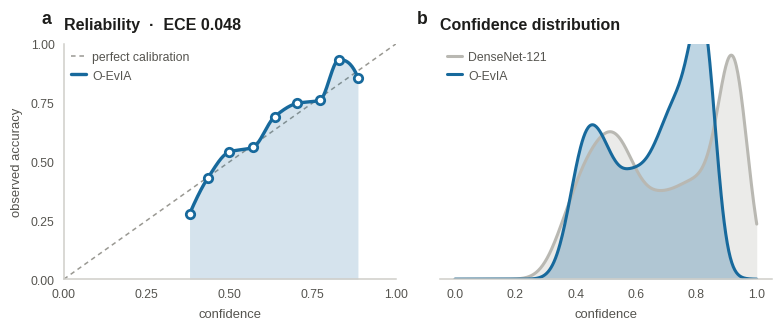

'/content/drive/MyDrive/EvIA_Knee/results/fig_reliability.png'

In [ ]:
def reliability(p, y, n_bins=15):
    """Bin by confidence, return (mean confidence, observed accuracy) per bin.
    Top-label calibration: confidence = max p, correct = argmax p equals the grade."""
    conf = p.max(1); acc = (p.argmax(1) == y).astype(float)
    ed = np.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for i in range(n_bins):
        m = (conf > ed[i]) & (conf <= ed[i+1])
        if m.sum() >= 5:
            xs.append(conf[m].mean()); ys.append(acc[m].mean())
    return np.array(xs), np.array(ys)

fig, ax = V.figure(1, 2, height=2.9)
V.diagonal(ax[0])
x, yv = reliability(p_mean, Yte, CFG.n_bins)
V.area(ax[0], x, yv, V.OURS, "O-EvIA", markers=True)
ax[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="confidence", ylabel="observed accuracy",
          title=f"Reliability  ·  ECE {E.ece(p_mean, Yte, CFG.n_bins):.3f}")
ax[0].set_xticks([0, .25, .5, .75, 1]); ax[0].set_yticks([0, .25, .5, .75, 1])
ax[0].spines["left"].set_visible(True)
V.legend(ax[0], loc="upper left")

fb = os.path.join(CFG.out_dir, "preds_densenet121_seed42.npz")
if os.path.exists(fb):                           # its own backbone, for contrast
    V.kde_area(ax[1], np.load(fb)["p"].max(1), V.COMPARATOR, "DenseNet-121", clip=(0, 1))
V.kde_area(ax[1], p_mean.max(1), V.OURS, "O-EvIA", clip=(0, 1))
ax[1].set(xlabel="confidence", title="Confidence distribution")
V.legend(ax[1], loc="upper left")
V.panel_letters(ax)
V.save(fig, "fig_reliability", CFG.out_dir)

In [ ]:
rows = []
for s in range(P.shape[0]):
    rows.append(dict(tag="EvIA-KL", seed=CFG.seeds[s],
                     ece=E.ece(P[s], Yte, CFG.n_bins), ace=E.ace(P[s], Yte, CFG.n_bins),
                     brier=E.brier(P[s], Yte), nll=E.nll(P[s], Yte),
                     aurc=E.aurc(U[s], E.decode(P[s]) == Yte)))

for name in ["densenet121", "resnet50", "efficientnetb0", "mobilenetv3s"]:   # all softmax baselines
    for s in CFG.seeds[:3]:
        f = os.path.join(CFG.out_dir, f"preds_{name}_seed{s}.npz")
        if not os.path.exists(f): continue
        z = np.load(f); p, u = z["p"], z["u"]
        rows.append(dict(tag=name, seed=s, ece=E.ece(p, Yte, CFG.n_bins),
                         ace=E.ace(p, Yte, CFG.n_bins), brier=E.brier(p, Yte),
                         nll=E.nll(p, Yte), aurc=E.aurc(u, E.decode(p) == Yte)))

CAL = pd.DataFrame(rows)
CAL.to_csv(os.path.join(CFG.out_dir, "calibration.csv"), index=False)
print("CALIBRATION (lower is better everywhere)")
print(CAL.groupby("tag")[["ece","ace","brier","nll","aurc"]].agg(["mean","std"]).round(4).to_string())

CALIBRATION (lower is better everywhere)
                   ece             ace           brier             nll            aurc        
                  mean     std    mean     std    mean     std    mean     std    mean     std
tag                                                                                           
EvIA-KL         0.0519  0.0182  0.0630  0.0094  0.4629  0.0486  0.8659  0.0766  0.2258  0.0681
densenet121     0.0520  0.0032  0.0550  0.0025  0.4518  0.0080  0.9322  0.0269  0.1735  0.0033
efficientnetb0  0.0312  0.0087  0.0339  0.0060  0.4816  0.0052  0.9059  0.0308  0.2043  0.0085
mobilenetv3s    0.0242  0.0028  0.0336  0.0075  0.5120  0.0057  1.0031  0.0460  0.2420  0.0104
resnet50        0.0473  0.0101  0.0492  0.0073  0.4628  0.0112  0.9598  0.1134  0.1835  0.0077


### 2. Does uncertainty rank the errors?

Sort by uncertainty, keep the most confident fraction, measure the error rate on what remains.
A steep fall means uncertainty really does find the mistakes — the property a deferral rule needs.

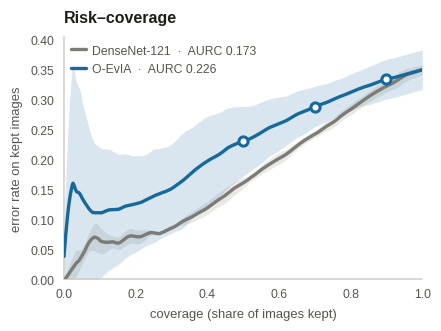

'/content/drive/MyDrive/EvIA_Knee/results/fig_riskcoverage.png'

In [ ]:
def risk_coverage(u, correct):
    o = np.argsort(u); err = (~correct[o]).astype(float)
    k = np.arange(1, len(err) + 1)
    return k / len(err), np.cumsum(err) / k

fig, ax = V.figure(1, 1, width=3.9, height=2.9)
cur = [risk_coverage(U[s], E.decode(P[s]) == Yte) for s in range(P.shape[0])]
mean_aurc = np.mean([E.aurc(U[s], E.decode(P[s]) == Yte) for s in range(P.shape[0])])
bc, ba = [], []                                  # its own backbone, for contrast
for s in CFG.seeds[:3]:
    f = os.path.join(CFG.out_dir, f"preds_densenet121_seed{s}.npz")
    if os.path.exists(f):
        z = np.load(f); ok = E.decode(z["p"]) == Yte
        bc.append(risk_coverage(z["u"], ok)); ba.append(E.aurc(z["u"], ok))
if bc:
    V.seed_curves(ax, [c[0] for c in bc], [c[1] for c in bc], V.COMPARATOR_DARK,
                  f"DenseNet-121  ·  AURC {np.mean(ba):.3f}", smooth_frac=0.05)
V.seed_curves(ax, [c[0] for c in cur], [c[1] for c in cur], V.OURS,
              f"O-EvIA  ·  AURC {mean_aurc:.3f}", smooth_frac=0.05,
              markers_at=[0.5, 0.7, 0.9])
ax.set(xlim=(0, 1), ylim=(0, None), xlabel="coverage (share of images kept)",
       ylabel="error rate on kept images", title="Risk–coverage")
ax.spines["left"].set_visible(True)
V.legend(ax, loc="upper left")
V.save(fig, "fig_riskcoverage", CFG.out_dir)

### 3. Is the evidential head worth it?

The fair comparison is not a raw softmax but a softmax with every remedy applied. Note the
`passes` column: that is the real inference cost of each uncertainty estimate.

In [ ]:
ds = E.load_knee(cfg=CFG, seed=42)
idx = ds["idx"]
print(f"{ds['name']}: {len(ds['y'])} images")
print("  grades    :", np.bincount(ds["y"], minlength=5))
print(f"  definite OA : {(ds['y']>=E.OA_THRESHOLD).sum()} "
      f"({(ds['y']>=E.OA_THRESHOLD).mean():.1%})")

# Decoded once into uint8 arrays and cached. A restarted session reloads in seconds.
data = {k: E.cached_split(ds["paths"][idx[k]], ds["y"][idx[k]], CFG, "knee_" + k, CACHE)
        for k in ("train", "val", "test")}
Xte, Yte = data["test"]
print(" ", {k: f"{v[0].shape} {v[0].dtype}" for k, v in data.items()})

  using the dataset's own train/val/test split
Knee OA (KL 0-4): 9786 images
  grades    : [3857 1770 2578 1286  295]
  definite OA : 4159 (42.5%)
  knee_train: loaded from cache
  knee_val: loaded from cache
  knee_test: loaded from cache
  {'train': '(5778, 224, 224, 3) uint8', 'val': '(826, 224, 224, 3) uint8', 'test': '(1656, 224, 224, 3) uint8'}


In [ ]:
rows = []
Xva, Yva = data["val"]
# One EfficientNet-B0 (seed 42) supplies softmax, temperature scaling and MC dropout.
# MC dropout now samples ONLY the dropout layer (batch norm stays in inference mode).
bm = E.train_baseline(data, "efficientnetb0", CFG, 42, verbose=0)

# every method gets the same val-fitted boundary step as EvIA-KL did in notebook 02
p0, _, _ = E.predict_baseline(bm, Xte, CFG)
p0 = E.calibrate_from(E.predict_baseline(bm, Xva, CFG)[0], Yva, p0); u0 = 1 - p0.max(1)
rows.append(dict(method="softmax", passes=1,
                 ece=E.ece(p0, Yte, CFG.n_bins), aurc=E.aurc(u0, E.decode(p0) == Yte)))

T = E.fit_temperature(bm, data["val"][0], data["val"][1], CFG)   # fitted on val, not test
pt, _, _ = E.predict_baseline(bm, Xte, CFG, temperature=T)
pt = E.calibrate_from(E.predict_baseline(bm, Xva, CFG, temperature=T)[0], Yva, pt)
ut = 1 - pt.max(1)
rows.append(dict(method=f"+ temperature (T={T:.2f})", passes=1,
                 ece=E.ece(pt, Yte, CFG.n_bins), aurc=E.aurc(ut, E.decode(pt) == Yte)))

pm, um, _ = E.mc_dropout_predict(bm, Xte, CFG, T=20)
pm = E.calibrate_from(E.mc_dropout_predict(bm, Xva, CFG, T=20)[0], Yva, pm)
rows.append(dict(method="+ MC dropout", passes=20,
                 ece=E.ece(pm, Yte, CFG.n_bins), aurc=E.aurc(um, E.decode(pm) == Yte)))

# Deep ensemble from the three EfficientNet-B0 seeds already trained in notebook 02
# (each already recalibrated on validation); uncertainty = mutual information.
Pe = np.stack([np.load(os.path.join(CFG.out_dir, f"preds_efficientnetb0_seed{s}.npz"))["p"]
               for s in (42, 43, 44)])
pe = Pe.mean(0)
H = lambda q: -(q * np.log(q + 1e-12)).sum(-1)
ue = H(pe) - H(Pe).mean(0)
rows.append(dict(method="+ deep ensemble (M=3)", passes=3,
                 ece=E.ece(pe, Yte, CFG.n_bins), aurc=E.aurc(ue, E.decode(pe) == Yte)))

rows.append(dict(method="O-EvIA (ordinal evidential)", passes=1,
                 ece=float(np.mean([E.ece(P[s], Yte, CFG.n_bins) for s in range(P.shape[0])])),
                 aurc=float(mean_aurc)))

UNC = pd.DataFrame(rows)
UNC.to_csv(os.path.join(CFG.out_dir, "uncertainty_methods.csv"), index=False)
print("UNCERTAINTY QUALITY vs INFERENCE COST")
print(UNC.round(4).to_string(index=False))
del bm; keras.backend.clear_session()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
UNCERTAINTY QUALITY vs INFERENCE COST
                     method  passes    ece   aurc
                    softmax       1 0.0413 0.2014
     + temperature (T=4.07)       1 0.0213 0.1898
               + MC dropout      20 0.0435 0.2206
      + deep ensemble (M=3)       3 0.0308 0.2988
O-EvIA (ordinal evidential)       1 0.0519 0.2258


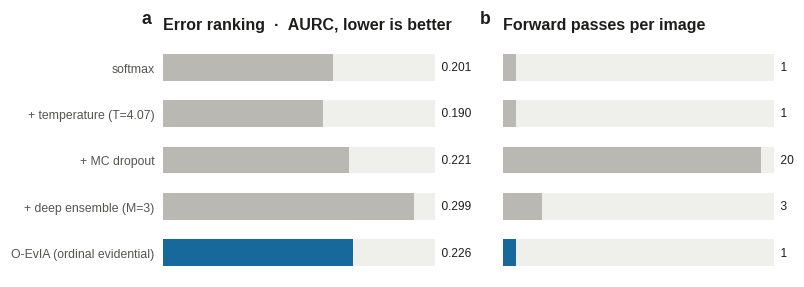

'/content/drive/MyDrive/EvIA_Knee/results/fig_uncertainty_cost.png'

In [ ]:
cols = [V.OURS if m.startswith("O-EvIA") else V.COMPARATOR for m in UNC.method]
fig, ax = V.figure(1, 2, width=7.2, height=2.5)
V.track_barh(ax[0], list(UNC.method), UNC.aurc.values, colors=cols, value_fmt="{:.3f}")
ax[0].set_title("Error ranking  ·  AURC, lower is better")
V.track_barh(ax[1], [""] * len(UNC), UNC.passes.values, colors=cols, value_fmt="{:.0f}",
             vmax=float(UNC.passes.max()) * 1.05)
ax[1].set_title("Forward passes per image")
V.panel_letters(ax)
V.save(fig, "fig_uncertainty_cost", CFG.out_dir)